# K-Means Clustering: Finding Hidden Patterns

Welcome to Unsupervised Learning! Unlike supervised models, we don't have a `TARGET` variable here. We just have raw data, and we need an algorithm to group similar data points together automatically.

In this notebook, we're building a robust K-Means clustering pipeline. We will focus heavily on **Variance Normalization (Whitening)**, which is the #1 step beginners forget, causing their clusters to fail horribly.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.vq import kmeans2, whiten

# Set up a clean plotting style
plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (10, 6)

## 1. Generating Complex Synthetic Data
Let's create 4 distinct groups of data. We'll add some noise so they overlap slightly, making the clustering task more realistic.

In [2]:
np.random.seed(40)

# Generate 4 clusters with different centers
c1 = np.random.randn(150, 2) + np.array([4, 4])
c2 = np.random.randn(150, 2) + np.array([-4, -4])
c3 = np.random.randn(150, 2) + np.array([4, -4])
c4 = np.random.randn(150, 2) + np.array([-4, 4])

# Stack them all together into one raw dataset and shuffle
raw_data = np.vstack((c1, c2, c3, c4))
np.random.shuffle(raw_data)

print(f"Created {raw_data.shape[0]} raw data points.")

Created 600 raw data points.


## 2. The Secret to Distance Algorithms: Whitening
K-Means groups data based on **Euclidean Distance** (straight-line distance). 
If one feature is measured in thousands (like Salary) and another in single digits (like Age), the Salary feature will completely dominate the distance calculation! 

We fix this using `whiten`, which normalizes every feature so its variance is exactly 1.0.

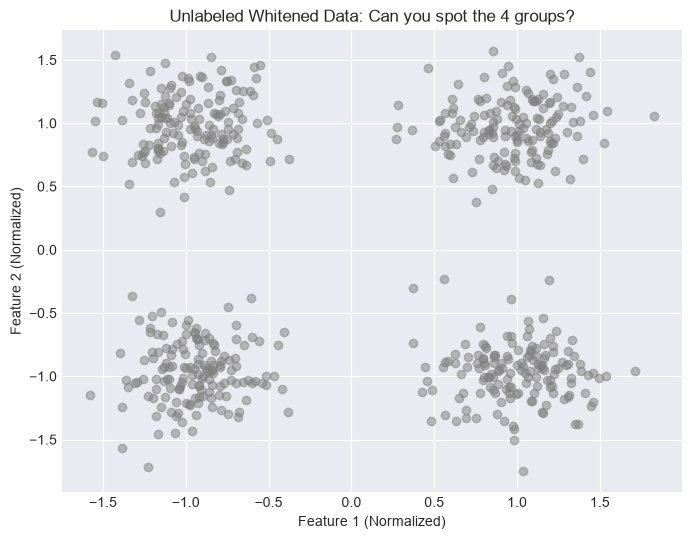

In [3]:
whitened_data = whiten(raw_data)

# Let's visualize the raw data without any labels
plt.figure(figsize=(8, 6))
plt.scatter(whitened_data[:, 0], whitened_data[:, 1], alpha=0.5, color='gray')
plt.title('Unlabeled Whitened Data: Can you spot the 4 groups?')
plt.xlabel('Feature 1 (Normalized)')
plt.ylabel('Feature 2 (Normalized)')
plt.show()

## 3. Running the K-Means Algorithm
To bypass `scikit-learn` system restrictions, we're using SciPy's highly optimized `kmeans2` engine. We explicitly tell it to look for `k=4` clusters, and we initialize the starting centroids using actual data points (`minit='points'`) to prevent the algorithm from getting stuck in a bad local minimum.

In [4]:
# Run the algorithm
centroids, cluster_labels = kmeans2(whitened_data, k=4, minit='points')

print("Algorithm finished! Found 4 centroids.")

Algorithm finished! Found 4 centroids.


## 4. Visualizing the Discovered Clusters
Let's color-code every point based on the cluster K-Means assigned it to, and prominently display the final centroids.

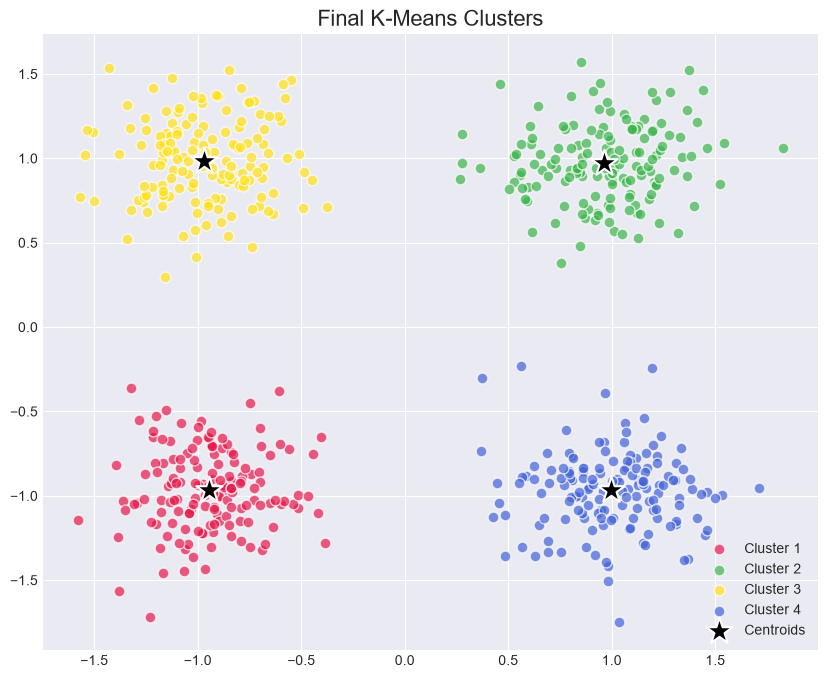

In [5]:
plt.figure(figsize=(10, 8))

# High-contrast colors for our 4 groups
colors = ['#e6194b', '#3cb44b', '#ffe119', '#4363d8']

for i in range(4):
    # Select all points assigned to cluster i
    cluster_points = whitened_data[cluster_labels == i]
    plt.scatter(cluster_points[:, 0], cluster_points[:, 1], 
                c=colors[i], alpha=0.7, edgecolors='white', s=60, label=f'Cluster {i+1}')

# Plot the massive black stars for the mathematical centers (centroids)
plt.scatter(centroids[:, 0], centroids[:, 1], 
            c='black', s=400, marker='*', edgecolor='white', linewidth=1.5, label='Centroids')

plt.title('Final K-Means Clusters', fontsize=16)
plt.legend()
plt.show()